In [1]:
import numpy as np 
import matplotlib.pyplot as plt

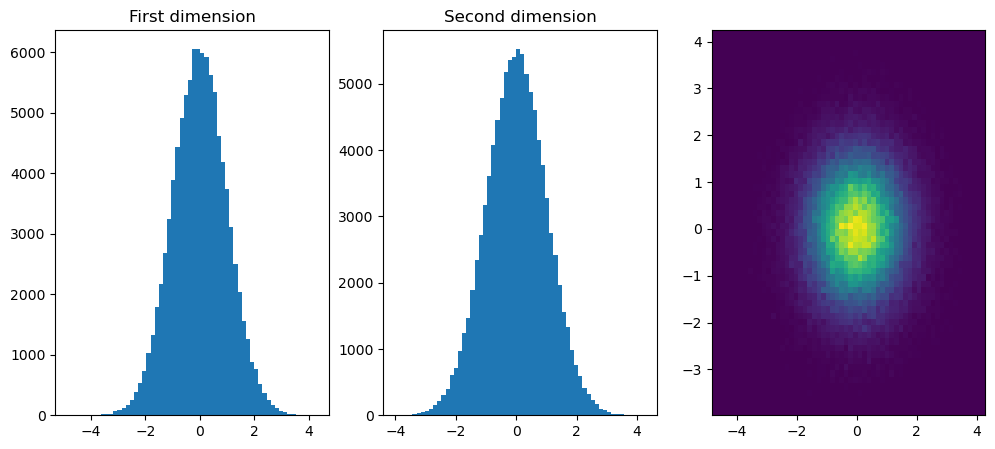

In [73]:
n = 100000
np.random.seed(0)

def generate_x(n,d=2):
    #return np.random.multivariate_normal(np.zeros(d), np.ones((d,d)), n)
    return np.random.multivariate_normal(np.zeros(d), np.eye(d), n)

#print(sampling_x(100, 2))

def plot_multivariate(n):
    x = generate_x(n)
    fig,ax = plt.subplots(1, 3, figsize=(12, 5))

    ax[0].hist(x[:,0], bins=60, label='first dimension')
    ax[0].set_title('First dimension')
    ax[1].hist(x[:,1], bins=60, label='second dimension')
    ax[1].set_title('Second dimension')

    ax[2].hist2d(x[:,0], x[:,1], bins=60 , density=True)
    plt.show()

plot_multivariate(n)

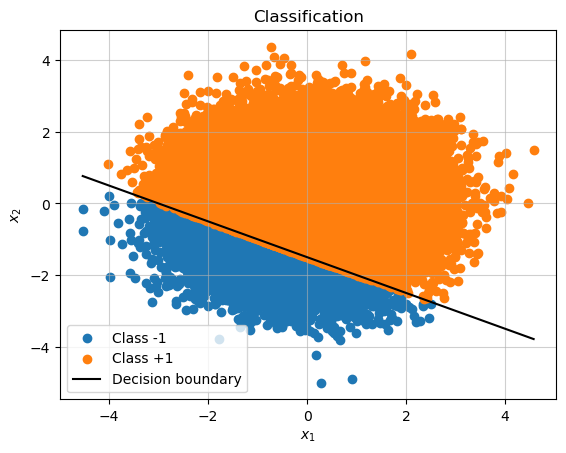

In [75]:
def generate_xy(n,w_star,tau_star):
    x = generate_x(n)
    y = np.array([np.sign(np.dot(w_star, x[i]) + tau_star) for i in range(n)])

    return x,y

w_star = (1,2) #meaning that the boundary is at y=-x/2
tau_star = 3

x,y = generate_xy(n, w_star, tau_star)

def plot_boundary(x, y, w_star, tau_star):
    plt.figure()
    plt.scatter(x[y == -1, 0], x[y == -1, 1], label='Class -1')
    plt.scatter(x[y == 1, 0], x[y == 1, 1], label='Class +1')

    # Decision boundary: w1*x1 + w2*x2 + tau = 0
    x_axis = np.linspace(x[:, 0].min(), x[:, 0].max(), 100)
    y_axis = -(w_star[0] * x_axis + tau_star) / w_star[1]

    plt.plot(x_axis, y_axis, 'k', label='Decision boundary')

    plt.title('Classification')
    plt.xlabel('$x_1$')
    plt.ylabel('$x_2$')
    plt.legend()
    plt.grid(alpha=0.6)
    
plot_boundary(x,y, w_star, tau_star)


In [77]:
def w_grad(w, tau, x_i, y_i):
    return -2*(y_i - np.dot(w,x_i) - tau)*x_i

def tau_grad(w, tau, x_i, y_i):
    return -2*(y_i - np.dot(w,x_i) - tau)

def SGD(x, y, eta, n_epochs, use_mini_batch=True, n_batch=10):
    w = np.array([1.0, 1.0])
    tau = 1.0
    n = len(x)

    w_history = [w.copy()]
    tau_history = [tau]

    for epoch in range(n_epochs):
        indices = np.random.permutation(n)

        if use_mini_batch:
            x_batches = np.array_split(x[indices], n_batch)
            y_batches = np.array_split(np.array(y)[indices], n_batch)

            for x_batch, y_batch in zip(x_batches, y_batches):
                grad = -2*(y_batch - x_batch @ w - tau)

                grad_w = np.mean(grad[:, None]*x_batch, axis=0)
                grad_tau = np.mean(grad)

                w -= eta*grad_w
                tau -= eta*grad_tau

                w_history.append(w.copy())
                tau_history.append(tau)

        else:
            for idx in indices:
                grad_w = w_grad(w, tau, x[idx], y[idx])
                grad_tau = tau_grad(w, tau, x[idx], y[idx])

                w -= eta*grad_w
                tau -= eta*grad_tau

                w_history.append(w.copy())
                tau_history.append(tau)

    return np.array(w_history), np.array(tau_history)


In [78]:
w_history, tau_history = SGD(x, y, eta=0.01, n_epochs=30, use_mini_batch=True, n_batch=10)

print("True w:", w_star)
print("Learned w:", w_history[-1])

print("True tau:", tau_star)
print("Learned tau:", tau_history[-1])

True w: (1, 2)
Learned w: [0.14926016 0.29208707]
True tau: 3
Learned tau: 0.8169332916276848


In [79]:
cos_sim = np.dot(w_history[-1], w_star) / (np.linalg.norm(w_history[-1]) * np.linalg.norm(w_star))
print("Cosine similarity:", cos_sim)

Cosine similarity: 0.9999615334548685


In [ ]:
def plot_history(w_history, tau_history):
    n = len(w_history)
    plt.figure()
